# 04 · Neural network and final comparison

**Goal:** train a neural network with the same rows and features as LightGBM, and compare all the models in the project, with confidence intervals that indicate whether the differences are real or within the noise.

**References to beat** (notebooks 02 and 03): SES + weekly index has an RMSSE of 0.742 (validation) and 0.769 (test); LightGBM, 0.740 and 0.768. It is practically a tie.

**Network design:**
- **Same direct strategy as LightGBM:** each row is a series, an origin, and a day of the horizon, with the same features, so that the only difference is the model.
- **Numeric features:** the highly skewed ones (sales and averages) are transformed with `log(1 + x)`, and all of them are standardized. Missing values are filled in and a missing indicator is added.
- **Categorical features with embeddings:** store, department, category, event type, and day of the week. An *embedding* is a low-dimensional numeric representation of each category, which the network learns during training.
- **Multilayer perceptron:** three hidden layers (256, 128, and 64 units) with a dropout of 0.1, and a positive output (`softplus` activation), because sales cannot be negative.
- **Loss function:** from the Tweedie family, as in LightGBM. The Poisson loss (exponent 1) and the Tweedie loss with exponent 1.5, which was the best in LightGBM, are compared.
- **Several networks with different seeds:** the training of a network depends on chance (initialization and data order). 3 networks are trained with different seeds and their forecasts are averaged, which reduces that variability.

**Protocol:** the one from notebook 01, the same as with LightGBM. The loss is chosen on validation (with the same holdout set for early stopping) and the model is retrained with data up to the test origin, which is evaluated only once.

## 1. Setup y datos

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import ensure_m5, load_calendar, load_prices, load_sales, day_columns, sample_series, SEED
from src.metrics import evaluar
from src.forecasting import (
    ventanas, guardar_resultados, pronostico_cero, pronostico_ingenuo,
    pronostico_ingenuo_estacional, pronostico_media_movil,
    pronostico_promedio_estacional, ses_semanal,
)
from src.gbm import HORIZONTE, preparar_contexto, construir_dataset, construir_varios, a_matriz
from src.nn import Preprocesador, entrenar_red, reentrenar_red
from src.comparacion import por_serie, bootstrap_pareado

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)
print("TensorFlow/Keras:", keras.__version__)

TensorFlow/Keras: 3.15.1


In [2]:
carpeta = ensure_m5()
calendario = load_calendar(carpeta)
precios = load_prices(carpeta)
ventas = load_sales(carpeta)
dias = day_columns(ventas)

muestra = sample_series(ventas, n_per_store=60, seed=SEED)
ctx = preparar_contexto(muestra, calendario, precios, dias)

Y = ctx["Y"]
n, T = Y.shape
H = HORIZONTE
V = ventanas(T, H)
o_val = V["validation"][0] - 1
o_test = V["test"][0] - 1
Y_train_val, Y_real_val = Y[:, :o_val], Y[:, o_val:o_val + H]
Y_train_test, Y_real_test = Y[:, :o_test], Y[:, o_test:o_test + H]
print(f"Series: {n} | days: {T} | validation origin: {o_val} | test origin: {o_test}")

Series: 600 | days: 1941 | validation origin: 1885 | test origin: 1913


## 2. Training sets

They are the same as in notebook 03: weekly origins that fall on the same day of the week as the origin being evaluated, the last `N_ORIGENES` (52 is equivalent to one year), with the 4 most recent reserved as a holdout set for early stopping (stopping training when the holdout error stops improving).

In [3]:
N_ORIGENES = 52
PASO = 7
N_CONTROL = 4
N_SEMILLAS = 3     # networks trained with different seeds, whose forecasts are averaged
EPOCAS_MAX = 30
BATCH = 1024

orig_val = [o_val - H - PASO * j for j in range(N_ORIGENES)]
orig_test = [o_test - H - PASO * j for j in range(N_ORIGENES)]

t0 = time.time()
X_ctrl, y_ctrl = construir_varios(ctx, orig_val[:N_CONTROL])
X_tr, y_tr = construir_varios(ctx, orig_val[N_CONTROL:])

prep = Preprocesador().fit(X_tr)
ent_tr, ent_ctrl = prep.transform(X_tr), prep.transform(X_ctrl)
print(f"Train: {len(X_tr):,} rows | control: {len(X_ctrl):,} rows | {time.time() - t0:.0f} s")
print(f"Numeric inputs: {len(prep.columnas)} | categories per embedding: {prep.n_cat}")

Train: 800,212 rows | control: 67,172 rows | 2 s
Numeric inputs: 33 | categories per embedding: {'tienda': 10, 'departamento': 7, 'categoria': 3, 'tipo_evento': 5, 'dia_semana': 7}


## 3. Choosing the loss (on validation)

3 networks are trained for each loss and averaged. The RMSSE and MAE of the average on the validation window are reported, along with the RMSSE of the individual networks (minimum and maximum), to see how much the result varies depending on the seed. The selection criterion is the RMSSE of the average.

In [4]:
def predecir_redes(modelos, prep_, origen):
    X, _, idx = construir_dataset(ctx, origen, con_objetivo=False)
    ent = prep_.transform(X)
    individuales = [a_matriz(m.predict(ent, batch_size=4096, verbose=0).ravel(), idx, n) for m in modelos]
    return np.mean(individuales, axis=0), individuales

PERDIDAS = {"Poisson": 1.0, "Tweedie 1,5": 1.5}
resumen, redes_val, preds_val, mejores_epocas, historiales = [], {}, {}, {}, {}

for nombre, p in PERDIDAS.items():
    t0 = time.time()
    modelos, epocas = [], []
    for s in range(N_SEMILLAS):
        m, mejor_ep, hist = entrenar_red(prep, ent_tr, y_tr, ent_ctrl, y_ctrl, p,
                                         semilla=SEED + s, epocas=EPOCAS_MAX, batch=BATCH)
        modelos.append(m)
        epocas.append(mejor_ep)
        if s == 0:
            historiales[nombre] = hist
    pred, individuales = predecir_redes(modelos, prep, o_val)
    m_prom = evaluar(Y_train_val, Y_real_val, pred)
    r_ind = [evaluar(Y_train_val, Y_real_val, pi)["RMSSE"] for pi in individuales]
    redes_val[nombre], preds_val[nombre], mejores_epocas[nombre] = modelos, pred, epocas
    fila = {"loss": nombre, "epoch": float(np.mean(epocas)), "RMSSE (networks mean)": m_prom["RMSSE"],
            "MAE (networks mean)": m_prom["MAE"], "RMSSE network min.": min(r_ind), "RMSSE network max.": max(r_ind),
            "minutes": (time.time() - t0) / 60}
    resumen.append(fila)
    print(f"{nombre:<12} epochs {fila['epoch']:.1f} | RMSSE {fila['RMSSE (networks mean)']:.3f} | "
          f"MAE {fila['MAE (networks mean)']:.3f} | individual network {min(r_ind):.3f}-{max(r_ind):.3f} | {fila['minutes']:.1f} min")

Poisson      epochs 7.7 | RMSSE 0.751 | MAE 1.013 | individual network 0.752-0.757 | 1.6 min
Tweedie 1,5  epochs 5.7 | RMSSE 0.749 | MAE 1.015 | individual network 0.746-0.755 | 1.3 min


In [5]:
tabla_nn = pd.DataFrame(resumen).set_index("loss")
mejor = tabla_nn["RMSSE (networks mean)"].idxmin()
print("Chosen loss (lowest RMSSE on validation):", mejor)
tabla_nn.round(3)

Chosen loss (lowest RMSSE on validation): Tweedie 1,5


,epoch,RMSSE (networks mean),MAE (networks mean),RMSSE network min.,RMSSE network max.,minutes
loss,,,,,,
Poisson,7.667,0.751,1.013,0.752,0.757,1.596
"Tweedie 1,5",5.667,0.749,1.015,0.746,0.755,1.316


**Reading.** The two exponents differ by 0.002: in RMSSE in favor of Tweedie 1.5 (0.749 versus 0.751) and in MAE in favor of Poisson (1.013 versus 1.015). The RMSSE range among the individual networks of each loss (0.746 to 0.755 and 0.752 to 0.757) is larger than that difference, so choosing between the two losses is in practice a tiebreak. The criterion set in advance (RMSSE of the average of the networks) selects Tweedie 1.5.

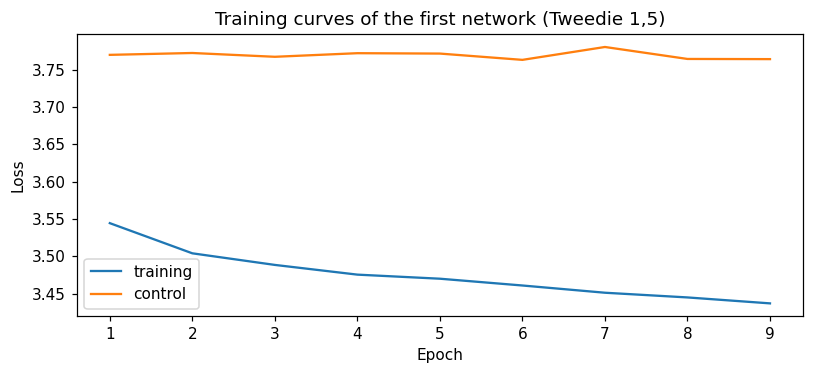

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.5))
h = historiales[mejor]
ax.plot(np.arange(1, len(h["loss"]) + 1), h["loss"], label="training")
ax.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], label="control")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title(f"Training curves of the first network ({mejor})")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Final model and evaluation on test

With the chosen loss and the average number of epochs decided by early stopping on validation, 3 networks are retrained with the origins up to `o_test − 28` (which include the data from the validation window), without a holdout set. It is evaluated on the test **only once**.

In [7]:
p_final = PERDIDAS[mejor]
epocas_final = max(1, int(round(np.mean(mejores_epocas[mejor]))))

t0 = time.time()
X_fin, y_fin = construir_varios(ctx, orig_test)
prep_fin = Preprocesador().fit(X_fin)
ent_fin = prep_fin.transform(X_fin)

redes_finales = [reentrenar_red(prep_fin, ent_fin, y_fin, p_final, epocas_final, semilla=SEED + s, batch=BATCH)
                 for s in range(N_SEMILLAS)]
pred_nn_test, ind_test = predecir_redes(redes_finales, prep_fin, o_test)
print(f"Retrained {N_SEMILLAS} networks with {len(X_fin):,} rows and {epocas_final} epochs in {(time.time() - t0) / 60:.1f} min")

m_val = evaluar(Y_train_val, Y_real_val, preds_val[mejor])
m_test = evaluar(Y_train_test, Y_real_test, pred_nn_test)
print(f"Validation -> RMSSE {m_val['RMSSE']:.3f} | MAE {m_val['MAE']:.3f}")
print(f"Test       -> RMSSE {m_test['RMSSE']:.3f} | MAE {m_test['MAE']:.3f}")

Retrained 3 networks with 868,588 rows and 6 epochs in 1.0 min
Validation -> RMSSE 0.749 | MAE 1.015
Test       -> RMSSE 0.772 | MAE 1.023


## 5. Comparison of all models

The forecasts of all the models are gathered for both windows: the baselines and SES (they are recomputed, because they are deterministic), LightGBM (read from `reports/predicciones_lightgbm.npz`) and the neural network. In addition, a **50/50 combination of LightGBM and the neural network** is added, a fixed rule defined in advance, not tuned to the results.

In [8]:
wday = calendario["wday"].to_numpy() - 1
categorias = muestra["cat_id"].astype(str).to_numpy()
origenes = {"validation": o_val, "test": o_test}
Y_tr = {"validation": Y_train_val, "test": Y_train_test}
Y_re = {"validation": Y_real_val, "test": Y_real_test}

lgbm = np.load(os.path.join(ROOT, "reports", "predicciones_lightgbm.npz"))
assert (lgbm["ids"] == muestra["id"].astype(str).to_numpy().astype("U")).all(), "The order of the series does not match that of notebook 03"

todas = {}
for v, o in origenes.items():
    Yh = Y_tr[v]
    todas[("Zero", v)] = pronostico_cero(Yh, H)
    todas[("Naive", v)] = pronostico_ingenuo(Yh, H)
    todas[("Stational naive", v)] = pronostico_ingenuo_estacional(Yh, H)
    todas[("28-day moving average", v)] = pronostico_media_movil(Yh, H)
    todas[("Seasonal average (4 weeks)", v)] = pronostico_promedio_estacional(Yh, H)
    todas[("SES + weekly index", v)] = ses_semanal(Yh, H, wday[:o], wday[o:o + H], categorias)[0]
    todas[("LightGBM", v)] = lgbm["validación" if v == "validación" else "test"]
todas[("Neural network", "validation")] = preds_val[mejor]
todas[("Neural network", "test")] = pred_nn_test
for v in origenes:
    todas[("Mean LightGBM + neural network", v)] = 0.5 * (todas[("LightGBM", v)] + todas[("Neural network", v)])

modelos_lista = list(dict.fromkeys(m for m, _ in todas))
filas = [{"model": m, "window": v, **evaluar(Y_tr[v], Y_re[v], todas[(m, v)])} for (m, v) in todas]
resultados = pd.DataFrame(filas)

tabla = resultados.pivot(index="model", columns="window", values=["RMSSE", "MAE"])
tabla = tabla[[("RMSSE", "validation"), ("RMSSE", "test"), ("MAE", "validation"), ("MAE", "test")]]
tabla.sort_values(("RMSSE", "test")).round(3)

RMSSE               MAE       
window                         validation   test validation   test
model                                                             
LightGBM                            0.709  0.768      0.959  1.011
Mean LightGBM + neural network      0.723  0.769      0.976  1.013
SES + weekly index                  0.742  0.769      1.036  1.008
Neural network                      0.749  0.772      1.015  1.023
28-day moving average               0.751  0.782      1.020  1.059
Seasonal average (4 weeks)          0.811  0.849      1.045  1.101
Zero                                0.940  0.990      1.392  1.477
Naive                               0.936  1.007      1.361  1.306
Stational naive                     0.995  1.029      1.195  1.233

**Reading.** At three decimal places there are ties: LightGBM has the lowest RMSSE on test (0.768), followed by the 50/50 combination and SES (0.769 both), and SES has the lowest MAE (1.008). The four best models are within 0.5% in RMSSE; the next section evaluates whether those differences exceed the noise across series.

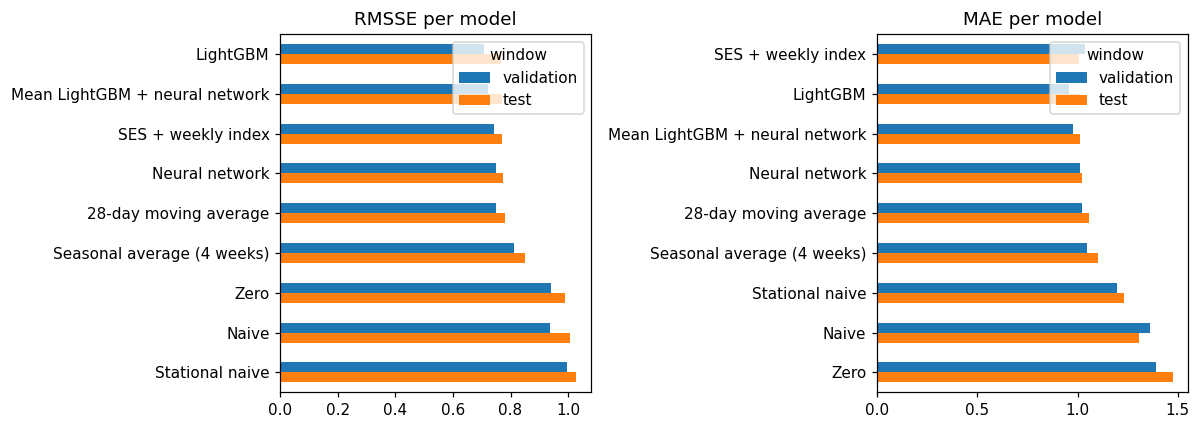

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica in zip(axes, ["RMSSE", "MAE"]):
    tabla[metrica].sort_values("test").plot.barh(ax=ax)
    ax.set_title(metrica + " per model")
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 5.1 Are the differences real? Bootstrap across series

The models above differ by hundredths. To know whether those differences are larger than the noise, the error of each series is computed with each model and they are compared in pairs with a **paired bootstrap**: the 600 series are resampled with replacement (5,000 times), preserving the pairing between models, and a 95% confidence interval of the mean error difference is obtained. A **negative** difference means that the first model makes fewer errors; `prob_A_mejor` is the proportion of resamples in which the first model has the lower error.

**What it includes and what it does not:** the bootstrap measures the variability due to *which series* were chosen, but not the variability due to *which time window* was evaluated: there is a single window per stage, and another window could give a different result.

In [10]:
rng = np.random.default_rng(SEED)
serie = {(m, v): por_serie(Y_tr[v], Y_re[v], todas[(m, v)]) for (m, v) in todas}

PARES = [
    ("LightGBM", "SES + weekly index"),
    ("Neural network", "SES + weekly index"),
    ("Neural network", "LightGBM"),
    ("Mean LightGBM + neural network", "SES + weekly index"),
    ("SES + weekly index", "28-day moving average"),
]

filas = []
for A, B in PARES:
    for v in origenes:
        for k, metrica in enumerate(["RMSSE", "MAE"]):
            r = bootstrap_pareado(serie[(A, v)][k], serie[(B, v)][k], n_boot=5000, rng=rng)
            filas.append({"comparison (A − B)": f"{A} − {B}", "window": v, "metric": metrica,
                          "dif": r["dif"], "ic_low": r["ic_bajo"], "ic_high": r["ic_alto"], "prob_A_better": r["prob_a_mejor"]})
boot = pd.DataFrame(filas)
boot["IC excludes 0"] = (boot["ic_low"] > 0) | (boot["ic_high"] < 0)
boot.round(4)

,comparison (A − B),window,metric,dif,ic_low,ic_high,prob_A_better,IC excludes 0
0,LightGBM − SES + weekly index,validation,RMSSE,-0.0329,-0.0411,-0.0247,1.0000,True
1,LightGBM − SES + weekly index,validation,MAE,-0.0769,-0.1455,-0.0169,0.9944,True
2,LightGBM − SES + weekly index,test,RMSSE,-0.0009,-0.0056,0.0039,0.6546,False
3,LightGBM − SES + weekly index,test,MAE,0.0035,-0.0120,0.0196,0.3238,False
4,Neural network − SES + weekly index,validation,RMSSE,0.0076,-0.0012,0.0183,0.0466,False
5,Neural network − SES + weekly index,validation,MAE,-0.0211,-0.0823,0.0296,0.7836,False
6,Neural network − SES + weekly index,test,RMSSE,0.0029,-0.0019,0.0080,0.1254,False
7,Neural network − SES + weekly index,test,MAE,0.0150,-0.0042,0.0391,0.0716,False
8,Neural network − LightGBM,validation,RMSSE,0.0405,0.0304,0.0517,0.0000,True
9,Neural network − LightGBM,validation,MAE,0.0558,0.0175,0.0987,0.0018,True


**Reading.** Of the 20 comparisons, 6 have an interval that excludes zero: neural network − LightGBM on validation (RMSSE and MAE), SES − moving average in RMSSE (in both windows) and in MAE on test, and LightGBM − SES in MAE on validation. With 20 95% intervals, roughly one can be expected to exclude zero by chance even if there were no real differences, and no correction for multiple comparisons was applied: differences that repeat across several metrics or windows are more reliable than those that appear in isolation.

**How much noise there is.** The RMSSE intervals have a half-width of 0.004 to 0.010 (between 0.5% and 1.3% of the RMSSE value), so, with respect to the variability across series, differences of less than about 1% cannot be distinguished from noise; this is what notebook 03 anticipated. The MAE intervals are much wider in relative terms: in LightGBM − SES on validation, the width is 0.012 in RMSSE (1.7% of the RMSSE of SES) and 0.111 in MAE (11% of the MAE of SES). In neural network − LightGBM on test, the RMSSE interval (−0.0004 to 0.0088) almost excludes zero and the probability that the network is better is 4%.

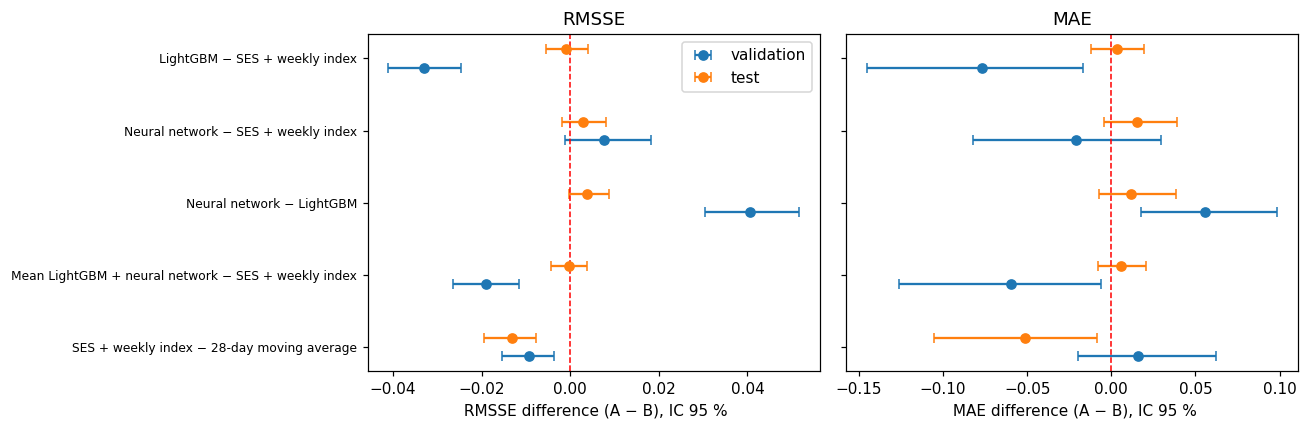

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
etiquetas = [f"{A} − {B}" for A, B in PARES]
for ax, metrica in zip(axes, ["RMSSE", "MAE"]):
    for k, (v, color) in enumerate([("validation", "tab:blue"), ("test", "tab:orange")]):
        t = boot[(boot["metric"] == metrica) & (boot["window"] == v)].set_index("comparison (A − B)").loc[etiquetas]
        y = np.arange(len(t))[::-1] + (k - 0.5) * 0.25
        ax.errorbar(t["dif"], y, xerr=[t["dif"] - t["ic_low"], t["ic_high"] - t["dif"]], fmt="o", capsize=3, color=color, label=v)
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_yticks(np.arange(len(etiquetas))[::-1])
    ax.set_yticklabels(etiquetas, fontsize=8)
    ax.set_xlabel(f" {metrica} difference (A − B), IC 95 %")
    ax.set_title(metrica)
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. Save results

In [12]:
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)
nuevos = resultados[resultados["model"].isin(["Neural network", "Mean LightGBM + red neuronal"])]
acumulado = guardar_resultados(nuevos, os.path.join(ROOT, "reports", "resultados_modelos.csv"))
resultados.to_csv(os.path.join(ROOT, "reports", "comparacion_final.csv"), index=False)
boot.to_csv(os.path.join(ROOT, "reports", "comparacion_bootstrap.csv"), index=False)
tabla_nn.to_csv(os.path.join(ROOT, "reports", "red_neuronal_experimentos.csv"))
np.savez(os.path.join(ROOT, "reports", "predicciones_red_neuronal.npz"),
         validacion=preds_val[mejor], test=pred_nn_test, ids=muestra["id"].astype(str).to_numpy().astype("U"))
print("Result saved in reports/")

Result saved in reports/


## 7. Conclusions

- **Choice of loss:** Poisson and Tweedie 1.5 give an RMSSE of 0.751 and 0.749 and an MAE of 1.013 and 1.015 on validation. The difference (0.002) is smaller than the variation across seeds of the same loss (RMSSE of the individual networks between 0.746 and 0.755 with Tweedie and between 0.752 and 0.757 with Poisson), and in MAE the order is reversed. Choosing Tweedie 1.5 for its lower RMSSE is a tiebreak and not a conclusive result. Early stopping chose on average 6 epochs (5.7 with Tweedie and 7.7 with Poisson) out of a maximum of 30, that is, the holdout error stops improving early. One possible explanation (unverified hypothesis) is that the rows of the same series and of nearby origins are highly correlated and provide less independent information than the 868,588 rows suggest.
- **Neural network (three averaged networks, retrained with 6 epochs):** RMSSE of 0.749 on validation and 0.772 on test, and MAE of 1.015 and 1.023.
- **Final comparison on test (RMSSE; MAE):** LightGBM (0.768; 1.011), the 50/50 combination of LightGBM and the network (0.769; 1.013), SES + weekly index (0.769; 1.008), neural network (0.772; 1.023), and 28-day moving average (0.782; 1.059). The 4-week seasonal average (0.849) and the naive models (1.007 and 1.029) are clearly behind. The four best models are within 0.5% in RMSSE, and the best one improves on the naive (1.007) by about 24% in RMSSE.
- **Which differences are real (bootstrap across series, 95% CI):** of the 20 comparisons, only 6 have an interval that excludes zero, and with 20 intervals roughly one can be expected by chance.
  - **SES beats the moving average in RMSSE in both windows** (−0.0093 on validation and −0.0131 on test, 1.2% and 1.7%) and in MAE on test (−0.051; in validation MAE the difference is +0.016 and the interval includes zero). It is the only difference that holds in both windows. This refines what was said in notebook 02, where the difference was measured without an interval and described as not conclusive: with respect to the variability across series it is reliable, but the variability across time windows is still not measured.
  - **The neural network performs worse than LightGBM** on validation (RMSSE +0.0093 and MAE +0.0316, with a probability that the network is better of less than 0.1%). On test the difference is smaller and the intervals include zero (RMSSE +0.0038, with a CI of −0.0004 to 0.0088, and a probability that the network is better of 4%; MAE +0.0116), but the sign is the same in all four combinations.
  - **LightGBM does not reliably beat SES.** Its MAE advantage on validation (−0.053, CI of −0.116 to −0.005) disappears on test (+0.0035, with a CI of −0.012 to 0.020), and in RMSSE the intervals include zero in both windows (−0.0018 and −0.0009). Since the LightGBM configuration was chosen among six on that same validation window, its result there is somewhat optimistic.
  - **The neural network does not beat SES either:** in RMSSE the difference is positive in both windows (+0.0076 and +0.0029), with intervals that include zero, and in MAE the signs are contradictory (−0.021 on validation and +0.015 on test), which indicates noise.
  - **The combination of LightGBM and the network adds nothing:** it is practically equal to SES in RMSSE (0.743 and 0.769; differences of +0.0010 and −0.0003 with intervals that include zero) and, in the four figures in the table, it is slightly behind LightGBM alone (0.743 versus 0.740 and 0.769 versus 0.768 in RMSSE; 0.994 versus 0.983 and 1.013 versus 1.011 in MAE), although that comparison was not evaluated with a bootstrap.
- **How much noise there is:** the RMSSE intervals have a half-width of 0.004 to 0.010 (0.5% to 1.3% of the RMSSE), so, with respect to the variability across series, differences of less than about 1% cannot be distinguished from noise. The MAE intervals are much wider in relative terms (in LightGBM − SES on validation, 0.111, 11% of the MAE of SES, versus 0.012 in RMSSE, 1.7% of the RMSSE of SES). One possible explanation (unverified hypothesis) is that the MAE is in units and a few high-volume series dominate it, while the RMSSE gives the same weight to each series; this is consistent with notebook 02, where the 45 smooth and erratic series accounted for about 31% of the absolute error of "Zero". On test, the network's point differences in MAE are positive relative to SES and LightGBM (+0.015 and +0.012), but their intervals include zero.
- **Variation across seeds:** the RMSSE of the individual Tweedie networks varies by up to 0.009 depending on the seed (0.746 to 0.755), more than the difference between LightGBM and SES (0.002 on validation and 0.001 on test). With a single network, the result would depend in good part on the seed; with only 3 networks, moreover, the observed range is a rough estimate of that variability.
- **General reading (unverified hypothesis):** at the product, store, and day level, demand is so sporadic and noisy that almost everything that can be predicted is in the recent level of sales. Weekly seasonality seems to contribute little at the series level: in notebook 02, SES (which uses a weekly index) beats the moving average (which does not) by only 1 to 2%, and in LightGBM the day of the week weighs 0.7% of the gain (notebook 03). The additional features (events, SNAP, prices, age) and the more flexible models do not produce a reliable improvement in these windows.
- **Limitations:** a single window per stage (the bootstrap covers the variability across series, but not across time windows) and no correction for multiple comparisons; 600 series out of 30,490; a validation window without events and a test window with minor events; LightGBM and network hyperparameters explored in a limited way (network architecture, learning rate, and regularization not tuned, and only two losses tested); a network that is a multilayer perceptron over the same features as LightGBM, so the results do not extend to sequential architectures such as LSTM or Transformers; only 3 seeds per network; RMSSE not weighted by revenue, unlike the competition's WRMSSE; and a single origin to estimate performance.
- **Future work:** evaluate with several consecutive origins to estimate the variability across windows, use all 30,490 series, tune the hyperparameters better, try sequential architectures, add features aggregated by store or product, and evaluate the WRMSSE.